# Two-neuron auditory-cortex model — early and late developmental regimes

This notebook documents an **exploratory computational neuroscience internship model** of responses to common (*standard*) and rare (*deviant*) auditory stimuli. It couples one subplate (SP) model neuron and one layer 4 (L4) model neuron to two stochastic thalamic input channels.

**Question:** How do synaptic-weight trajectories and spiking change when the relative influence of subplate input, direct thalamic drive, and short-term synaptic recovery are altered between *early* and *late* developmental regimes?

The system is phenomenological and has not been experimentally validated. The figures below are newly generated from a seeded run of this notebook, not reproductions of earlier saved plots.

## 1. Model structure and stimulus sequence

```text
Standard thalamic input ──┬──► SP neuron ──► L4 neuron
                          └────────────────► L4 neuron
Deviant thalamic input ───┬──► SP neuron
                          └────────────────► L4 neuron
```

**Stochastic input:** Each token lasts **300 ms**, comprising an active 50-ms window followed by 250 ms of low-rate activity. A standard token occurs with probability **0.9**, and a deviant token with probability **0.1**. The active channel fires at **50 Hz** (sampled independently at 1-ms intervals); the non-active channel has a background rate of **0.15 Hz**, and both channels have **0.1-Hz** spontaneous activity in the remaining 250 ms.

The active rate was increased from **8 Hz to 50 Hz** during exploratory tuning to produce more visible spiking; it is **not** an experimental estimate.

Each input train is filtered with an exponential kernel of synaptic time constant 10 ms, truncated at 100 ms:

$$g(t)=\sum_{s=0}^{99} u(t-s)\exp(-s/10).$$

Here time is measured in milliseconds and $u(t)$ is the binary spike indicator.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print('NumPy:', np.__version__)

NumPy: 2.3.5


In [2]:
def thalamic_input_generator(standard_token_prob, num_tokens, rng):
    
    standard_prob = standard_token_prob
    deviant_prob = 1.0 - standard_token_prob
    # Standard represented by 1
    # Deviant represented by 0
    token_sequence = rng.choice([0,1],size=num_tokens,p=[deviant_prob,standard_prob])

    # Each token is 50ms followed by 250 ms of silence ; total 300ms per token
    simulation_array_length = len(token_sequence)*300
    standard_channel = np.zeros(simulation_array_length) 
    deviant_channel = np.zeros(simulation_array_length) 

    # When we have standard token, frequency on standard channel = 50Hz, frequency on deviant channel = 0.15Hz
    # When we have deviant token, frequency on deviant channel = 50Hz, frequency on standard channel = 0.15Hz

    # Defining probabilities per millisecond: 
    # Sampling rate = 1000/s
    # Therefore, 8 occurences per 1000 time steps => 0.008 (8.0/1000.0) probability of it happening per time step
    p_high = 50.0/1000.0 # changed from 8 to 50Hz to fortify early regime behavior
    p_low = 0.15/1000.0 
    p_spont = 0.1/1000.0 

    # punching values onto the channel arrays
    for index, token in enumerate(token_sequence):
        start_idx = index*300
        token_end_idx = start_idx + 50
        silence_end_idx = start_idx + 300

        if token == 1: # Standard token 
            standard_channel[start_idx:token_end_idx] = rng.random(50) < p_high 
            deviant_channel[start_idx:token_end_idx] = rng.random(50) < p_low 
        else: # Deviant token
            deviant_channel[start_idx:token_end_idx] = rng.random(50) < p_high
            standard_channel[start_idx:token_end_idx] = rng.random(50) < p_low

        # Implimenting 250 ms silent window with background noise 
        standard_channel[token_end_idx:silence_end_idx] = rng.random(250) < p_spont
        deviant_channel[token_end_idx:silence_end_idx] = rng.random(250) < p_spont 

    return token_sequence, standard_channel, deviant_channel, simulation_array_length

In [3]:
# Each spike train will get its corresponding conductance 
# gstd for standard_channel
# gdev for deviant_channel 

# g(t) = spike_train*k(t) ; k(t) is the convolution kernel

def conductance_convolve(spike_train_array):

    conductance_array = np.zeros(len(spike_train_array)) # initialising an array to store conductance values
    tau_syn = 10 # ms

    # Creating a decay kernel having conductance profile over a time range
    t_window = np.arange(0,100)
    kernel = np.exp((-t_window/tau_syn)) # This creates a 100ms array having the profile of conductance

    # 2. Convolve the spike train with the kernel
    # mode='full' ensures all spikes are captured, but makes the array slightly longer, 
    # slicing to keep the exact original length.
    conductance_array = np.convolve(spike_train_array, kernel, mode='full')[:len(spike_train_array)]
    
    return conductance_array

## 2. Neuron dynamics and developmental parameters

The model uses **discrete leaky integrate-and-fire updates**. Outside a 20-ms refractory interval, the abstract voltage state follows

$$v_{t+1}=0.9 v_t+I_t.$$

A spike is emitted if $v_{t+1}\geq\theta$; the state is then reset to $-5$ and follows a prescribed recovery curve. Voltage and synaptic amplitudes are in **arbitrary model units**, not calibrated millivolts or conductances.

### Parameter differences

| Parameter | Early (before ear-canal opening) | Late (after ear-canal opening) |
|---|---:|---:|
| SP threshold | 0.10 | 0.15 |
| Initial standard → L4 weight | 0.02 | 0.12 |
| Initial deviant → L4 weight | 0.02 | 0.12 |
| Initial SP → L4 weight | 0.22 | 0.04 |
| Inactive → recovered synaptic-resource time | 4200 ms | 100 ms |

The L4 threshold remains **0.15**, and the thalamic → SP weight remains **0.2**. These regime-specific values were **hand-tuned in the original internship notebook** and should not be interpreted as independently fitted developmental measurements.

In [4]:
# PARAMETER INITIALIZATION

def initialize_params(regime, simulation_array_length):
    """
    Initializes all parameters, state variables, and recording arrays for the SNN.
    regime: 0 for EARLY REGIME (Before ECO), 1 for LATE REGIME (After ECO)
    """
    
    # ---------------------------------------------------------
    # 1. REGIME-DEPENDENT LOGIC
    # ---------------------------------------------------------
    if regime == 0: # EARLY REGIME
        sp_thresh = 0.10
        
        w_inp_l4_std = 0.02
        w_inp_l4_dev = 0.02
        w_sp_l4 = 0.22
        
        tau_ir_thal = 4200.0  # Slow recovery (Oddball selectivity ON)
        tau_ir_sp = 4200.0
        
    elif regime == 1: # LATE REGIME
        sp_thresh = 0.15 
        
        w_inp_l4_std = 0.12   # Strong Thalamic drive
        w_inp_l4_dev = 0.12
        w_sp_l4 = 0.04        # Weakened SP drive
        
        tau_ir_thal = 100.0   # Fast recovery (Oddball selectivity OFF)
        tau_ir_sp = 100.0
    else:
        raise ValueError("Regime must be 0 (Early) or 1 (Late)")

    # ---------------------------------------------------------
    # 2. STATIC PARAMETERS & TRACKERS
    # ---------------------------------------------------------
    l4_thresh = 0.15
    w_inp_sp = 0.2 
    
    tau_syn = 10 # ms
    decay_factor_syn = np.exp(-1.0/tau_syn)
    g_sp_l4 = 0.0
    
    sp_spiked_this_step = 0.0

    # LIF Trackers
    last_spike_sp = -1000
    last_spike_l4 = -1000
    
    # Old STDP Trackers (Kept for backwards compatibility)
    last_spike_std = -1000
    last_spike_dev = -1000
    
    # New STDP Trackers (Nearest-Neighbor)
    stdp_pre_std = -1000
    stdp_pre_dev = -1000
    stdp_pre_sp = -1000
    stdp_post_std = -1000
    stdp_post_dev = -1000
    stdp_post_sp = -1000

    # Tsodyks-Markram Static Taus & Initial States
    tau_re_thal, tau_ei_thal = 0.9, 10.0
    tau_re_sp, tau_ei_sp = 0.9, 27.0
    
    x_r_std, x_e_std, x_i_std = 1.0, 0.0, 0.0
    x_r_dev, x_e_dev, x_i_dev = 1.0, 0.0, 0.0
    x_r_sp, x_e_sp, x_i_sp  = 1.0, 0.0, 0.0

    # ---------------------------------------------------------
    # 3. RECORDING ARRAYS & LISTS
    # ---------------------------------------------------------
    sp_spiketimes = [] 
    l4_spiketimes = []
    
    # Pack everything into a dictionary to return cleanly
    return {
        # Arrays
        'v_sp': np.zeros(simulation_array_length),
        'v_l4': np.zeros(simulation_array_length),
        'g_sp_l4_record': np.zeros(simulation_array_length),
        'w_inp_l4_std_record': np.zeros(simulation_array_length),
        'w_inp_l4_dev_record': np.zeros(simulation_array_length),
        'w_sp_l4_record': np.zeros(simulation_array_length),
        'x_r_std_record': np.zeros(simulation_array_length),
        'x_e_std_record': np.zeros(simulation_array_length),
        'x_i_std_record': np.zeros(simulation_array_length),
        'x_r_dev_record': np.zeros(simulation_array_length),
        'x_e_dev_record': np.zeros(simulation_array_length),
        'x_i_dev_record': np.zeros(simulation_array_length),
        'x_r_sp_record': np.zeros(simulation_array_length),
        'x_e_sp_record': np.zeros(simulation_array_length),
        'x_i_sp_record': np.zeros(simulation_array_length),
        'sp_spiketimes': sp_spiketimes,
        'l4_spiketimes': l4_spiketimes,
        
        # State Variables
        'x_r_std': x_r_std, 'x_e_std': x_e_std, 'x_i_std': x_i_std,
        'x_r_dev': x_r_dev, 'x_e_dev': x_e_dev, 'x_i_dev': x_i_dev,
        'x_r_sp': x_r_sp, 'x_e_sp': x_e_sp, 'x_i_sp': x_i_sp,
        'w_inp_l4_std': w_inp_l4_std,
        'w_inp_l4_dev': w_inp_l4_dev,
        'w_sp_l4': w_sp_l4,
        'g_sp_l4': g_sp_l4,
        'sp_spiked_this_step': sp_spiked_this_step,
        
        # Trackers
        'last_spike_sp': last_spike_sp, 'last_spike_l4': last_spike_l4,
        'last_spike_std': last_spike_std, 'last_spike_dev': last_spike_dev,
        'stdp_pre_std': stdp_pre_std, 'stdp_pre_dev': stdp_pre_dev, 'stdp_pre_sp': stdp_pre_sp,
        'stdp_post_std': stdp_post_std, 'stdp_post_dev': stdp_post_dev, 'stdp_post_sp': stdp_post_sp,
        
        # Fixed Parameters
        'l4_thresh': l4_thresh, 'sp_thresh': sp_thresh,
        'w_inp_sp': w_inp_sp,
        'tau_syn': tau_syn, 'decay_factor_syn': decay_factor_syn,
        'tau_re_thal': tau_re_thal, 'tau_ei_thal': tau_ei_thal, 'tau_ir_thal': tau_ir_thal,
        'tau_re_sp': tau_re_sp, 'tau_ei_sp': tau_ei_sp, 'tau_ir_sp': tau_ir_sp
    }

## 3. Short-term depression and spike-timing-dependent plasticity

**Short-term depression:** Each presynaptic pathway has recovering ($r$), effective ($e$), and inactive ($i$) resource fractions. For a binary presynaptic spike indicator $s_t$, the 1-ms update is

$$\begin{aligned}
f_{r\to e} &= s_t\min(r/\tau_{re},r),\\
f_{e\to i} &= e/\tau_{ei},\\
f_{i\to r} &= i/\tau_{ir},\\
r' &= r + f_{i\to r}-f_{r\to e},\\
e' &= e + f_{r\to e}-f_{e\to i},\\
i' &= i + f_{e\to i}-f_{i\to r}.
\end{aligned}$$

This is a simple discrete three-pool synaptic-resource model inspired by the Tsodyks–Markram formulation.

**STDP:** A selected recent pre/post spike pair produces a multiplicative update to the current weight $w$:

$$\Delta w=\begin{cases}
+w A_+e^{-(t_{post}-t_{pre})/\tau_+}, & t_{post}\geq t_{pre},\\
-w A_-e^{-(t_{pre}-t_{post})/\tau_-}, & t_{post}<t_{pre}.
\end{cases}$$

The code uses $A_+=0.015$, $\tau_+=13$ ms, $A_-=0.021$, $\tau_-=20$ ms, and a 100-ms recent-event window. It pairs the most recently stored eligible events rather than summing over every possible spike pair. We bound all three plastic weights to $[0,1]$ to avoid numerical runaway.

In [5]:
# Functions for updating variables 

def update_synaptic_resources(spike_flag, x_r, x_e, x_i, tau_re, tau_ei, tau_ir):
    """
    Calculates the discrete flow of synaptic resources.
    spike_flag: 1.0 if a presynaptic spike arrived this step, 0.0 otherwise.
    """
    # 1. Calculate flows
    flow_r2e = spike_flag * (x_r / tau_re)
    if flow_r2e > x_r: flow_r2e = x_r # Safeguard against over-depletion
    
    flow_e2i = x_e / tau_ei
    flow_i2r = x_i / tau_ir

    # 2. Update states
    new_x_r = x_r + flow_i2r - flow_r2e
    new_x_e = x_e + flow_r2e - flow_e2i
    new_x_i = x_i + flow_e2i - flow_i2r
    
    return new_x_r, new_x_e, new_x_i

def calculate_stdp_weight_change(current_weight, t_post, t_pre, amp_strength=0.015, tau_strength=13.0, amp_weak=0.021, tau_weak=20.0):
    """
    Calculates the weight change based on the temporal order of spikes.
    If POST >= PRE: Potentiation (LTP) - Includes simultaneous spikes!
    If PRE > POST: Depression (LTD)
    """
    if t_post >= t_pre: # <--- ADDED EQUALS SIGN HERE
        # LTP (Strengthening)
        delta_t = t_post - t_pre
        delta_w = current_weight * (amp_strength * np.exp(-delta_t / tau_strength))
    elif t_pre > t_post:
        # LTD (Weakening)
        delta_t = t_pre - t_post
        delta_w = current_weight * (-amp_weak * np.exp(-delta_t / tau_weak))
    else:
        delta_w = 0.0 
        
    return delta_w

def update_lif_neuron(t, v_prev, total_input_drive, last_spike_time, threshold, beta=5.0, tau_decay=2.0, refr_window=20):
    """
    Updates membrane potential and checks for spikes.
    Returns the new voltage, a boolean spike flag, and the updated last_spike_time.
    """
    spiked_this_step = 0.0
    
    # 1. Check Refractory Status
    if (t - last_spike_time) < refr_window:
        # Hyperpolarization recovery curve
        v_new = -beta * np.exp(-(t - last_spike_time) / tau_decay)
    else:
        # Normal Euler Integration (10% leak + input drive)
        v_new = (v_prev * 0.9) + total_input_drive
        
    # 2. Check Threshold
    if v_new >= threshold:
        v_new = -beta
        spiked_this_step = 1.0
        last_spike_time = t + 1 # Record the spike
        
    return v_new, spiked_this_step, last_spike_time

## 4. Simulation function

The original single-regime simulation has been reorganized as a function that initializes independent state arrays for **each** developmental regime. The core LIF, synaptic-resource, and pairwise-STDP update rules are retained. State recordings are aligned with the time step, and plastic weights are bounded.

In [6]:
def simulate_regime(regime, standard_channel, deviant_channel, gstd, gdev):
    """Simulate one developmental regime with freshly initialized state variables."""
    simulation_array_length = len(standard_channel)
    if not (len(deviant_channel) == len(gstd) == len(gdev) == simulation_array_length):
        raise ValueError("Input arrays have incompatible lengths")
    # 1. Call the function (Set to 0 for Early, 1 for Late)
    init_data = initialize_params(regime=regime, simulation_array_length=simulation_array_length)

    # 2. Unpack Arrays and Lists
    v_sp , v_l4 = init_data['v_sp'] , init_data['v_l4']
    sp_spiketimes , l4_spiketimes = init_data['sp_spiketimes'] , init_data['l4_spiketimes']

    g_sp_l4_record = init_data['g_sp_l4_record']

    w_inp_l4_std_record = init_data['w_inp_l4_std_record'] 
    w_inp_l4_dev_record = init_data['w_inp_l4_dev_record'] 
    w_sp_l4_record = init_data['w_sp_l4_record']
    x_r_std_record = init_data['x_r_std_record'] 
    x_e_std_record = init_data['x_e_std_record'] 
    x_i_std_record = init_data['x_i_std_record']
    x_r_dev_record = init_data['x_r_dev_record']
    x_e_dev_record = init_data['x_e_dev_record']
    x_i_dev_record = init_data['x_i_dev_record']
    x_r_sp_record = init_data['x_r_sp_record']  
    x_e_sp_record = init_data['x_e_sp_record']
    x_i_sp_record = init_data['x_i_sp_record']


    # 3. Unpack State Variables
    x_r_std, x_e_std, x_i_std = init_data['x_r_std'], init_data['x_e_std'], init_data['x_i_std']
    x_r_dev, x_e_dev, x_i_dev = init_data['x_r_dev'], init_data['x_e_dev'], init_data['x_i_dev']
    x_r_sp, x_e_sp, x_i_sp = init_data['x_r_sp'], init_data['x_e_sp'], init_data['x_i_sp']
    w_inp_l4_std , w_inp_l4_dev , w_sp_l4 = init_data['w_inp_l4_std'] , init_data['w_inp_l4_dev'] , init_data['w_sp_l4']
    g_sp_l4 = init_data['g_sp_l4']
    sp_spiked_this_step = init_data['sp_spiked_this_step']

    # 4. Unpack Trackers
    last_spike_sp = init_data['last_spike_sp']
    last_spike_l4 = init_data['last_spike_l4']
    last_spike_std = init_data['last_spike_std']
    last_spike_dev = init_data['last_spike_dev']
    stdp_pre_std = init_data['stdp_pre_std']
    stdp_pre_dev = init_data['stdp_pre_dev']
    stdp_pre_sp = init_data['stdp_pre_sp']
    stdp_post_std = init_data['stdp_post_std']
    stdp_post_dev = init_data['stdp_post_dev']
    stdp_post_sp = init_data['stdp_post_sp']

    # 5. Unpack Fixed Parameters
    l4_thresh = init_data['l4_thresh']
    sp_thresh = init_data['sp_thresh']
    w_inp_sp = init_data['w_inp_sp']
    tau_syn = init_data['tau_syn']
    decay_factor_syn = init_data['decay_factor_syn']
    tau_re_thal = init_data['tau_re_thal']
    tau_ei_thal = init_data['tau_ei_thal']
    tau_ir_thal = init_data['tau_ir_thal']
    tau_re_sp = init_data['tau_re_sp']
    tau_ei_sp = init_data['tau_ei_sp']
    tau_ir_sp = init_data['tau_ir_sp']
    w_max = 1.0
    for t in range(simulation_array_length - 1):

        # ---------------------------------------------------------
        # 1. SYNAPTIC RESOURCE DYNAMICS (Tsodyks-Markram)
        # ---------------------------------------------------------
        x_r_std, x_e_std, x_i_std = update_synaptic_resources(standard_channel[t], x_r_std, x_e_std, x_i_std, tau_re_thal, tau_ei_thal, tau_ir_thal)
        x_r_dev, x_e_dev, x_i_dev = update_synaptic_resources(deviant_channel[t], x_r_dev, x_e_dev, x_i_dev, tau_re_thal, tau_ei_thal, tau_ir_thal)
        x_r_sp,  x_e_sp,  x_i_sp  = update_synaptic_resources(sp_spiked_this_step, x_r_sp, x_e_sp, x_i_sp, tau_re_sp, tau_ei_sp, tau_ir_sp)
    
        # ---------------------------------------------------------
        # 2. STDP: DEPRESSION (LTD) - Thalamic Inputs
        # ---------------------------------------------------------
        if standard_channel[t] == 1:
            stdp_pre_std = t
            if stdp_post_std >= 0 and (t - stdp_post_std) < 100:
                w_inp_l4_std += calculate_stdp_weight_change(w_inp_l4_std, stdp_post_std, t)
                stdp_post_std, stdp_pre_std = -1000, -1000  

        if deviant_channel[t] == 1:
            stdp_pre_dev = t
            if stdp_post_dev >= 0 and (t - stdp_post_dev) < 100:
                w_inp_l4_dev += calculate_stdp_weight_change(w_inp_l4_dev, stdp_post_dev, t)
                stdp_post_dev, stdp_pre_dev = -1000, -1000

        # ---------------------------------------------------------
        # 3. SP NEURON DYNAMICS
        # ---------------------------------------------------------
        sp_drive = (gstd[t] * w_inp_sp * x_e_std) + (gdev[t] * w_inp_sp * x_e_dev)
        v_sp[t+1], sp_spiked_this_step, last_spike_sp = update_lif_neuron(t, v_sp[t], sp_drive, last_spike_sp, sp_thresh)

        if sp_spiked_this_step == 1.0:
            sp_spiketimes.append(last_spike_sp)
            stdp_pre_sp = t + 1
        
            # SP spike acts as PRE to L4 -> Trigger LTD
            if stdp_post_sp >= 0 and (t + 1 - stdp_post_sp) < 100:
                w_sp_l4 += calculate_stdp_weight_change(w_sp_l4, stdp_post_sp, t + 1)
                stdp_post_sp, stdp_pre_sp = -1000, -1000

        # Update continuous SP -> L4 conductance
        g_sp_l4 = (g_sp_l4 * decay_factor_syn) + sp_spiked_this_step 
        g_sp_l4_record[t+1] = g_sp_l4

        # ---------------------------------------------------------
        # 4. L4 NEURON DYNAMICS
        # ---------------------------------------------------------
        l4_drive = (gstd[t] * w_inp_l4_std * x_e_std) + (gdev[t] * w_inp_l4_dev * x_e_dev) + (g_sp_l4 * w_sp_l4 * x_e_sp)
        v_l4[t+1], l4_spiked_this_step, last_spike_l4 = update_lif_neuron(t, v_l4[t], l4_drive, last_spike_l4, l4_thresh)

        # ---------------------------------------------------------
        # 5. STDP: POTENTIATION (LTP) - L4 Spikes
        # ---------------------------------------------------------
        if l4_spiked_this_step == 1.0:
            l4_spiketimes.append(last_spike_l4)

            # Evaluate Standard Synapse
            if stdp_pre_std >= 0 and (t + 1 - stdp_pre_std) < 100:
                w_inp_l4_std += calculate_stdp_weight_change(w_inp_l4_std, t + 1, stdp_pre_std)
                w_inp_l4_std = min(w_inp_l4_std,w_max)
                stdp_pre_std, stdp_post_std = -1000, -1000
            else:
                stdp_post_std = t + 1

            # Evaluate Deviant Synapse
            if stdp_pre_dev >= 0 and (t + 1 - stdp_pre_dev) < 100:
                w_inp_l4_dev += calculate_stdp_weight_change(w_inp_l4_dev, t + 1, stdp_pre_dev)
                w_inp_l4_dev = min(w_inp_l4_dev,w_max)
                stdp_pre_dev, stdp_post_dev = -1000, -1000
            else:
                stdp_post_dev = t + 1

            # Evaluate SP Synapse
            if stdp_pre_sp >= 0 and (t + 1 - stdp_pre_sp) < 100:
                w_sp_l4 += calculate_stdp_weight_change(w_sp_l4, t + 1, stdp_pre_sp)
                w_sp_l4 = min(w_sp_l4,w_max)
                stdp_pre_sp, stdp_post_sp = -1000, -1000
            else:
                stdp_post_sp = t + 1
            
        # Bound all plastic weights to avoid runaway updates and negative weights.
        w_inp_l4_std = max(0.0, min(w_inp_l4_std, w_max))
        w_inp_l4_dev = max(0.0, min(w_inp_l4_dev, w_max))
        w_sp_l4 = max(0.0, min(w_sp_l4, w_max))

        # ---------------------------------------------------------
        # 6. RECORDING STATES
        # ---------------------------------------------------------
        w_inp_l4_std_record[t+1] = w_inp_l4_std
        w_inp_l4_dev_record[t+1] = w_inp_l4_dev
        w_sp_l4_record[t+1] = w_sp_l4

        x_r_std_record[t+1], x_e_std_record[t+1], x_i_std_record[t+1] = x_r_std, x_e_std, x_i_std
        x_r_dev_record[t+1], x_e_dev_record[t+1], x_i_dev_record[t+1] = x_r_dev, x_e_dev, x_i_dev
        x_r_sp_record[t+1],  x_e_sp_record[t+1],  x_i_sp_record[t+1]  = x_r_sp,  x_e_sp,  x_i_sp


    # t=0 is the initial weight, before any updates.
    w_inp_l4_std_record[0] = init_data['w_inp_l4_std']
    w_inp_l4_dev_record[0] = init_data['w_inp_l4_dev']
    w_sp_l4_record[0] = init_data['w_sp_l4']
    for arr in (w_inp_l4_std_record, w_inp_l4_dev_record, w_sp_l4_record, v_sp, v_l4):
        if not np.all(np.isfinite(arr)):
            raise FloatingPointError('Non-finite states produced by simulation')
    return dict(regime=regime, sp_spiketimes=np.array(sp_spiketimes, dtype=int),
                l4_spiketimes=np.array(l4_spiketimes, dtype=int),
                w_std=w_inp_l4_std_record, w_dev=w_inp_l4_dev_record,
                w_sp=w_sp_l4_record, v_sp=v_sp, v_l4=v_l4,
                resources_final={'standard': (x_r_std, x_e_std, x_i_std),
                                 'deviant': (x_r_dev, x_e_dev, x_i_dev),
                                 'SP': (x_r_sp, x_e_sp, x_i_sp)})


## 5. Run both regimes with identical random input

We generate the thalamic stimulus once with a fixed random seed and reuse it for both developmental regimes. The default **1,000 tokens** correspond to **300 seconds** of simulated time. The original working notebook also experimented with 5,000 tokens; increase `NUM_TOKENS` for longer trajectories at the cost of execution time.

In [7]:
RNG_SEED = 2026
STANDARD_TOKEN_PROBABILITY = 0.90
NUM_TOKENS = 1000  # 300 s at 300 ms per token

rng = np.random.default_rng(RNG_SEED)
token_sequence, standard_channel, deviant_channel, simulation_array_length = (
    thalamic_input_generator(STANDARD_TOKEN_PROBABILITY, NUM_TOKENS, rng)
)
gstd = conductance_convolve(standard_channel)
gdev = conductance_convolve(deviant_channel)
print('Duration (s):', simulation_array_length / 1000)
print('Token counts (standard, deviant):', int(np.sum(token_sequence == 1)),
      int(np.sum(token_sequence == 0)))
print('Spike counts (standard, deviant):', int(np.sum(standard_channel)),
      int(np.sum(deviant_channel)))

Duration (s): 300.0
Token counts (standard, deviant): 910 90
Spike counts (standard, deviant): 2249 261


In [8]:
print('Running early regime...')
early = simulate_regime(0, standard_channel, deviant_channel, gstd, gdev)
print('Running late regime with the SAME input spike trains...')
late = simulate_regime(1, standard_channel, deviant_channel, gstd, gdev)
print('Simulation complete.')

Running early regime...


Running late regime with the SAME input spike trains...


Simulation complete.


## 6. Numerical sanity checks and results

Inspect the final weights and spike counts. We also test that the three synaptic-resource pools remain nonnegative and sum to one, and that the three plastic weights remain bounded. These are **internal numerical checks**, not biological validation.

In [9]:
for label, result in [('Early', early), ('Late', late)]:
    print(f'\n{label}: SP spikes = {len(result["sp_spiketimes"])}; '
          f'L4 spikes = {len(result["l4_spiketimes"])}')
    print(f'  Final direct weights (standard → L4, deviant → L4): '
          f'{result["w_std"][-1]:.5f}, {result["w_dev"][-1]:.5f}')
    print(f'  Final SP → L4 weight: {result["w_sp"][-1]:.5f}')
    for source, resources in result['resources_final'].items():
        assert np.all(np.array(resources) >= -1e-10), (label, source, resources)
        assert np.isclose(sum(resources), 1.0, atol=1e-8), (label, source, resources)
    for name in ('w_std', 'w_dev', 'w_sp'):
        assert np.min(result[name]) >= 0 and np.max(result[name]) <= 1
print('Numerical checks passed.')


Early: SP spikes = 152; L4 spikes = 126
  Final direct weights (standard → L4, deviant → L4): 0.03056, 0.05410
  Final SP → L4 weight: 1.00000

Late: SP spikes = 1288; L4 spikes = 2060
  Final direct weights (standard → L4, deviant → L4): 1.00000, 0.73360
  Final SP → L4 weight: 1.00000
Numerical checks passed.


## 7. Figures and exports

Each figure combines: (1) a raster plot over the **first 30 seconds**, (2) the evolution of both **thalamic → L4** weights over the *whole* simulation, and (3) the **SP → L4** weight over the *whole* simulation. The 30-second raster view is deliberately shorter than the full 300-second weight trajectory so individual spikes can be seen.

Run the final two cells to generate **`Early_Regime.png`** and **`Late_Regime.png`** using `plt.savefig`.

In [10]:
def plot_regime(result, standard_channel, deviant_channel, raster_seconds=30):
    """Create the spike raster (first 30 s) and full-duration weight curves."""
    name = 'Early' if result['regime'] == 0 else 'Late'
    n = len(standard_channel)
    raster_end = min(n, int(raster_seconds * 1000))
    duration_s = n / 1000
    time_s = np.arange(n) / 1000
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 9.5),
                     gridspec_kw={'height_ratios': [1.2, 1.0, 0.75]})
    events = [
       (np.flatnonzero(standard_channel[:raster_end]), 4, 'green', 'Standard input'),
       (np.flatnonzero(deviant_channel[:raster_end]), 3, 'red', 'Deviant input'),
       (result['sp_spiketimes'][result['sp_spiketimes'] < raster_end], 2, 'purple', 'SP spikes'),
       (result['l4_spiketimes'][result['l4_spiketimes'] < raster_end], 1, 'orange', 'L4 spikes'),
    ]
    for spike_steps, row, color, label in events:
        ax1.eventplot(spike_steps / 1000, lineoffsets=row, linelengths=.7,
                      colors=color, linewidths=.75, label=label)
    ax1.set_yticks([1, 2, 3, 4])
    ax1.set_yticklabels(['L4 spikes', 'SP spikes', 'Deviant input', 'Standard input'])
    ax1.set_xlim(0, raster_end/1000)
    ax1.set_ylim(.5, 4.5)
    ax1.set_xlabel('Time (s)')
    ax1.set_title(f'Spike raster — first {raster_end/1000:g} s')
    ax1.legend(loc='upper right', ncol=2, fontsize=8)
    ax1.grid(axis='x', alpha=.15)

    ax2.plot(time_s, result['w_std'], color='green', lw=1.4, label='Standard → L4')
    ax2.plot(time_s, result['w_dev'], color='red', lw=1.4, label='Deviant → L4')
    ax2.set_xlim(0, duration_s)
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Weight (a.u.)')
    ax2.set_title('Direct thalamic → L4 weights (entire simulation)')
    ax2.legend()
    ax2.grid(alpha=.25)

    ax3.plot(time_s, result['w_sp'], color='purple', lw=1.4, label='SP → L4')
    ax3.set_xlim(0, duration_s)
    ax3.set_xlabel('Time (s)')
    ax3.set_ylabel('Weight (a.u.)')
    ax3.set_title('SP → L4 weight (entire simulation)')
    ax3.legend()
    ax3.grid(alpha=.25)

    fig.suptitle(f'{name} developmental regime: two-neuron model', fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, .965])
    return fig


### Early developmental regime

This run starts with comparatively strong subplate → L4 coupling and slow resource recovery. The figure is a model output under the explicitly stated parameter settings, not evidence of experimentally established oddball selectivity.

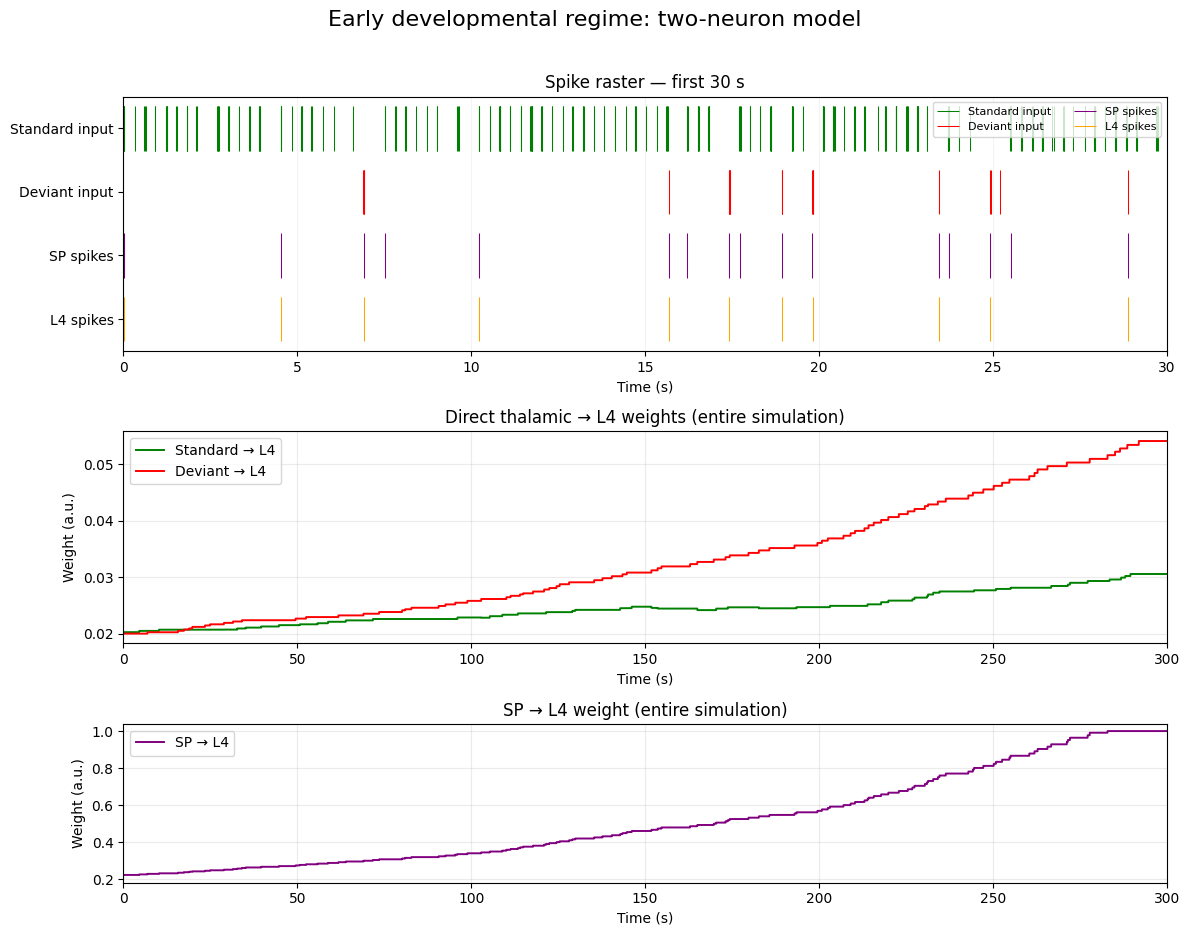

Saved: Early_Regime.png


In [11]:
fig_early = plot_regime(early, standard_channel, deviant_channel)
plt.figure(fig_early.number)
plt.savefig('Early_Regime.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: Early_Regime.png')

### Late developmental regime

This run starts with stronger direct thalamic → L4 connections, weaker subplate → L4 coupling, and faster recovery. Because the **input channels are identical** across the two runs, differences arise from regime parameters and ensuing recurrent state changes rather than from a newly drawn stimulus.

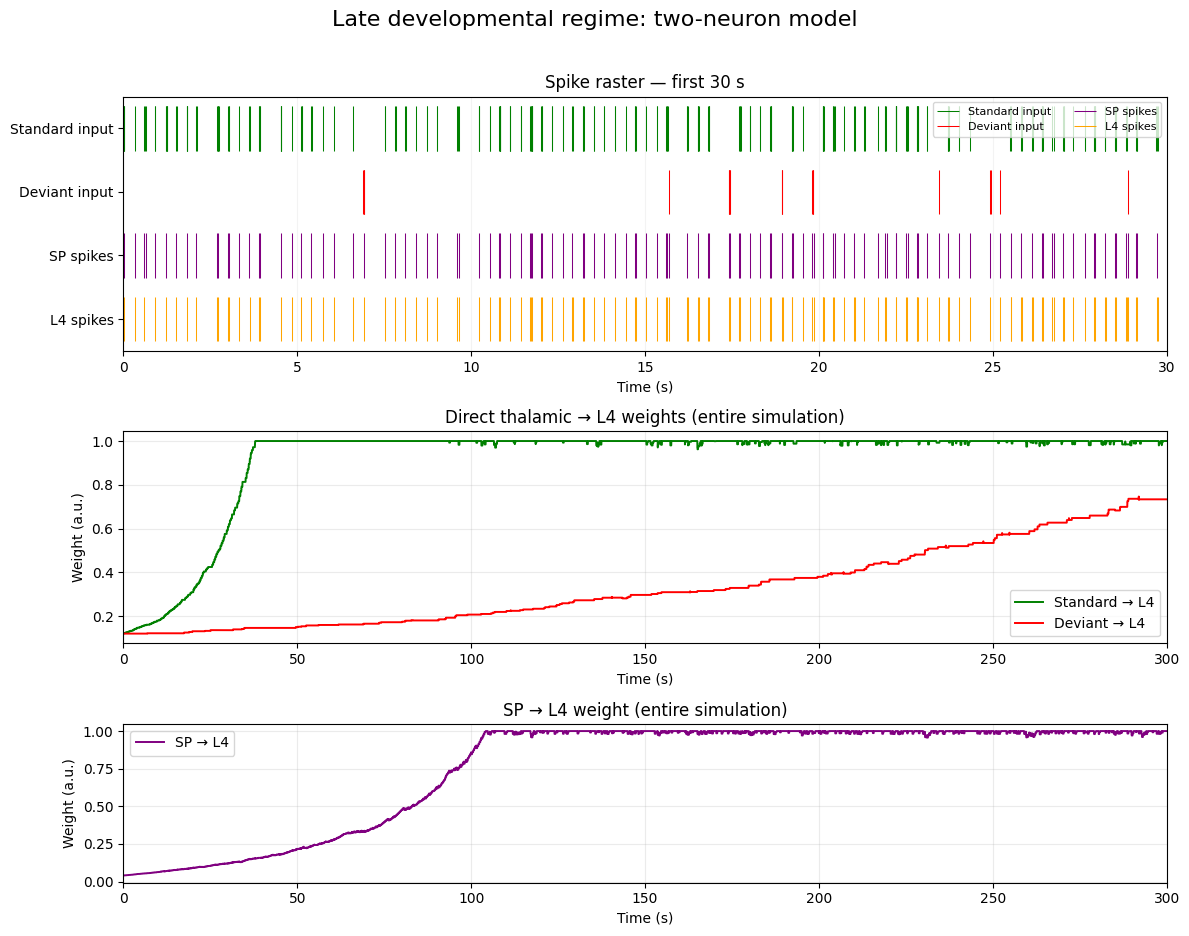

Saved: Late_Regime.png


In [12]:
fig_late = plot_regime(late, standard_channel, deviant_channel)
plt.figure(fig_late.number)
plt.savefig('Late_Regime.png', dpi=180, bbox_inches='tight')
plt.show()
print('Saved: Late_Regime.png')

## 8. Limitations and interpretation

- The model contains only **one SP and one L4 neuron**; larger-scale auditory circuitry, cell-type diversity, and recurrent network effects are not represented.
- Parameters and the **50-Hz** active input rate were tuned during exploratory work; they are **not fits** to experimental spike recordings.
- The LIF voltage variables, conductances, and plastic weights use abstract units.
- STDP uses a recent-event pairing heuristic and bounded weights. Other pairing methods or bounds may change results.
- **Weight saturation in this example:** the SP → L4 weight reaches the imposed upper bound of 1.0 in both regimes, and the standard → L4 weight reaches that bound in the late run. Saturation is a feature of this simplified learning rule and cap, **not a validated biological prediction**.
- A single random seed cannot establish robustness. Before claiming systematic developmental differences, repeat the calculation over many independent input sequences and report variation.
- Results demonstrate **qualitative model behaviour**, not validated mechanisms of developmental auditory oddball processing.

**Reproducibility:** Running all cells in order will create both figures in the notebook's current working directory, with `RNG_SEED` and `NUM_TOKENS` controlling the example.